## Importación de librerías

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Semilla para reproducibilidad de resultados

In [2]:
np.random.seed(42)
tf.random.set_seed(42)

## Sección 1: División de datos y escalado (preparación para Deep Learning)

In [3]:
# 1. Cargar el dataset limpio de la Actividad Fundamental 1
df = pd.read_csv('healthcare-dataset-stroke-data-limpio.csv')

# Separar variables predictoras (X) y variable objetivo (y)
X = df.drop(columns=['stroke'])
y = df['stroke']

# Asegurar que todas las variables categóricas estén codificadas numéricamente (si aún no lo están)
X = pd.get_dummies(X, drop_first=True)

# 2. División 80% entrenamiento y 20% prueba manteniendo la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Distribución original de clases:\n{y.value_counts(normalize=True)}")
print(f"\nDistribución en entrenamiento:\n{y_train.value_counts(normalize=True)}")
print(f"\nDistribución en prueba:\n{y_test.value_counts(normalize=True)}")

# 3. Escalado de variables
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Distribución original de clases:
stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64

Distribución en entrenamiento:
stroke
0    0.951321
1    0.048679
Name: proportion, dtype: float64

Distribución en prueba:
stroke
0    0.951076
1    0.048924
Name: proportion, dtype: float64


## Sección 2: Diseño de la arquitectura y selección de funciones (`Keras`/`TensorFlow`)

In [4]:
# Obtener el número de características de entrada
num_features = X_train_scaled.shape[1]

# 1. Construcción del modelo secuencial con dos capas ocultas
model = keras.Sequential([
    layers.Input(shape=(num_features,)),

    # Primera capa oculta
    layers.Dense(64, activation='relu', name='capa_oculta_1'),
    layers.Dropout(0.3),  # Regularización para prevenir sobreajuste

    # Segunda capa oculta
    layers.Dense(32, activation='relu', name='capa_oculta_2'),
    layers.Dropout(0.2),

    # 2. Capa de salida para clasificación binaria
    layers.Dense(1, activation='sigmoid', name='capa_salida')
])

# Mostrar resumen de la arquitectura
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ capa_oculta_1 (Dense)           │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_oculta_2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ capa_salida (Dense)             │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,201 (12.50 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 0 (0.00 B)

## Sección 3: Entrenamiento, métricas y optimizadores

In [5]:
# 1. Compilación del modelo con optimizador Adam y métricas para desbalance
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=[
        keras.metrics.AUC(name='auc'),
        keras.metrics.Recall(name='recall'),
        keras.metrics.Precision(name='precision'),
        'accuracy'
    ]
)

# Configurar EarlyStopping monitoreando el AUC de validación
early_stop = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# 2. Entrenamiento del modelo con conjunto de validación (20% del conjunto de entrenamiento)
history = model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

# Evaluación final en el conjunto de prueba
resultados_test = model.evaluate(X_test_scaled, y_test, return_dict=True, verbose=0)
for nombre, valor in resultados_test.items():
    print(f"Test {nombre}: {valor:.4f}")

Epoch 1/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9064 - auc: 0.5025 - loss: 0.3039 - precision: 0.0523 - recall: 0.0592 - val_accuracy: 0.9425 - val_auc: 0.6869 - val_loss: 0.2067 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - auc: 0.7310 - loss: 0.1743 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9425 - val_auc: 0.7881 - val_loss: 0.1940 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - auc: 0.7628 - loss: 0.1689 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9425 - val_auc: 0.8140 - val_loss: 0.1876 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/100
103/103 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - auc: 0.8130 - loss: 0.1584 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.9425 - val_auc: 0.8250 - val_loss: 0.1851 - val_precision: 0.0000e+

### Extra:

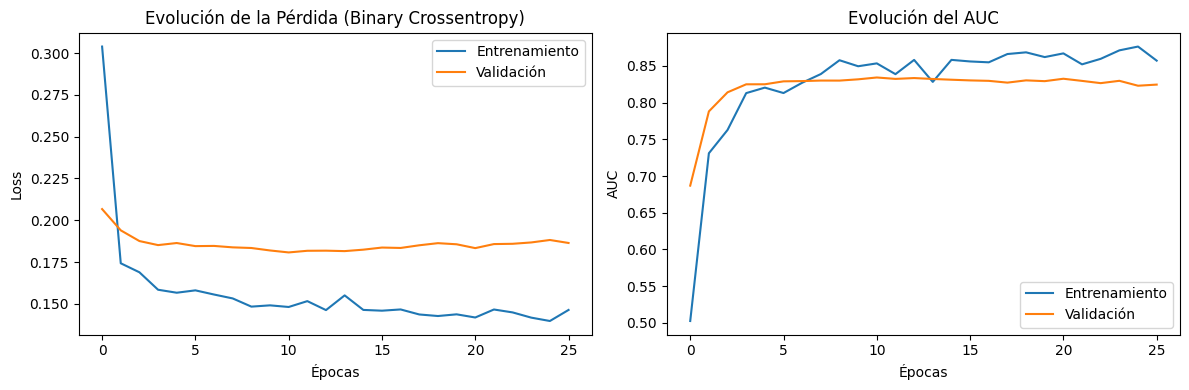

In [6]:
import matplotlib.pyplot as plt


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Curva de pérdida (Loss)
ax1.plot(history.history['loss'], label='Entrenamiento')
ax1.plot(history.history['val_loss'], label='Validación')
ax1.set_title('Evolución de la Pérdida (Binary Crossentropy)')
ax1.set_xlabel('Épocas')
ax1.set_ylabel('Loss')
ax1.legend()

# Curva de AUC
ax2.plot(history.history['auc'], label='Entrenamiento')
ax2.plot(history.history['val_auc'], label='Validación')
ax2.set_title('Evolución del AUC')
ax2.set_xlabel('Épocas')
ax2.set_ylabel('AUC')
ax2.legend()

plt.tight_layout()
plt.show()